In [1]:
import sys
import colorsys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
from matplotlib import cm 
from epiweeks import Week
import matplotlib.pyplot as plt 
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
from aux_func import get_data, code_to_state
from epiweeks import Week 

# Definir a cor das bordas (spines) como cinza
mpl.rcParams['axes.edgecolor'] = 'gray'

# Definir a cor das linhas dos ticks maiores e menores como cinza
mpl.rcParams['xtick.color'] = 'gray'
mpl.rcParams['ytick.color'] = 'gray'
mpl.rcParams['xtick.labelcolor'] = 'black'
mpl.rcParams['ytick.labelcolor'] = 'black'
plt.rcParams['axes.labelsize'] = 14 # Axis labels
plt.rcParams['xtick.labelsize'] = 12  # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12  # Y-axis tick labels
plt.rcParams['font.size'] = 14  # General font size
FONT = 12

Challenge:

In [2]:
challenge = 'dengue_city'
col_region = 'adm_2'

if challenge == 'dengue_city': 

    disease = 'Dengue'

    geocodes = [2931350,2933307,2302503,3119401,
                  3549805,3541406,1200401,1200203,
                  1716109,4113700,4103701,4104808,
                  5201405,5102637,5215231]

elif challenge == 'chik_city': 

    disease = 'Chikungunya'
    

    geocodes = [2211001,2931350,3143302,3119401,
            1721000,1716109,4104808,4219507,
            5103403,5102637] 

remove_models = ['3rd_imdc_-unifesp-_-4mosqueteiras-',
                                      '3rd_imdc_fiocruz_zerolags',
                                        '3rd_imdc_rki_rki_zki_ph',
                               '3rd_imdc_rki_rki_zki_ph_lstm_geo',
                                         '3rd_imdc_unesp_recogna',
 '3rd_imdc_universidad_del_valle_grupo_modelamiento_datos_dengue',
 '3rd_imdc_unesp_recogna_daniel']

Load data: 

In [3]:
df_dengue_state = get_data(challenge)
df_dengue_state.date = pd.to_datetime(df_dengue_state.date)
df_dengue_state.head()

,date,adm_2,casos
0,2010-01-03,4113700,14
1,2010-01-03,2302503,0
2,2010-01-03,4103701,0
3,2010-01-03,3541406,4
4,2010-01-03,3119401,8


In [4]:
casos_2026 = df_dengue_state.loc[df_dengue_state.date >= pd.to_datetime(Week(2025, 41).startdate())].rename(columns = {'casos':'casprov_2026'})

casos_2026.head()

,date,adm_2,casprov_2026
12330,2025-10-05,1716109,1
12331,2025-10-05,5201405,211
12332,2025-10-05,4103701,15
12333,2025-10-05,1200401,12
12334,2025-10-05,2302503,1


Load forecasts:

In [5]:
df_for = pd.read_csv(f'./predictions/forecast_all_models_{challenge}.csv.gz', index_col = 'Unnamed: 0')
df_for.date = pd.to_datetime(df_for.date)
df_for = df_for.loc[~df_for.model.isin(remove_models)]
#df_for = df_for.loc[df_for[col_region] != 32]

df_for.head()

,date,lower_95,lower_90,lower_80,lower_50,pred,upper_50,upper_80,upper_90,upper_95,adm_2,id,validation,model
780,2026-10-11,0.024717,0.041244,0.102585,0.301943,1.311677,5.059768,14.451320,30.575402,44.130657,2931350,14004,Forecast,3rd_imdc_emap_lstm_muni
781,2026-10-18,0.032611,0.059003,0.137782,0.502689,1.868866,5.491871,17.733885,39.238301,60.347400,2931350,14004,Forecast,3rd_imdc_emap_lstm_muni
782,2026-10-25,0.015177,0.032742,0.085030,0.307743,1.121309,4.232050,12.525038,23.402618,39.344678,2931350,14004,Forecast,3rd_imdc_emap_lstm_muni
783,2026-11-01,0.028762,0.044769,0.127912,0.423790,1.430360,5.476913,18.760642,31.867937,49.821311,2931350,14004,Forecast,3rd_imdc_emap_lstm_muni
784,2026-11-08,0.014884,0.033059,0.063121,0.226481,0.814174,2.931963,11.644227,26.774754,41.047947,2931350,14004,Forecast,3rd_imdc_emap_lstm_muni


Load ensemble: 

In [7]:
df_median_ens = pd.read_csv(f'./predictions/ensemble_weekly_2026_{challenge}.csv.gz')
df_median_ens.date = pd.to_datetime(df_median_ens.date)
df_median_ens.head()

,date,adm_2,lower_95,lower_90,lower_80,lower_50,pred,upper_50,upper_80,upper_90,upper_95
0,2026-10-11,1200203,0.029684,0.164766,0.565111,2.095487,9.822588,21.393518,33.590177,93.177359,151.683158
1,2026-10-11,1200401,0.542310,1.035545,2.774073,4.458344,10.210685,19.606250,32.775767,47.034943,85.756946
2,2026-10-11,1716109,0.000054,0.000157,0.055880,0.201414,1.347089,3.381098,8.481363,14.518647,22.420662
3,2026-10-11,2302503,0.000082,0.000293,0.000971,0.051871,1.332635,2.102035,6.344745,12.321510,17.223097
4,2026-10-11,2931350,0.011761,0.020622,0.075209,0.492997,3.328960,8.352021,19.518590,35.287701,53.077828


Load population:

In [9]:
df_pop = pd.read_csv('data/datasus_population_2001_2025.csv.gz')

df_pop = df_pop.loc[df_pop.year == 2025].rename(columns = {'geocode': 'adm_2'})

df_pop.head() 

,adm_2,year,population
133680,3539905,2025,5702
133681,3540408,2025,4182
133682,3540309,2025,2411
133683,3540259,2025,4198
133684,3540200,2025,38286


In [12]:
df_inc = casos_2026.merge(df_pop, on = col_region)
df_inc['inc'] = 100000*df_inc['casprov_2026']/df_inc['population']
df_inc.head()

,date,adm_2,casprov_2026,year,population,inc
0,2025-10-05,1716109,1,2025,55704,1.795203
1,2025-10-05,5201405,211,2025,556021,37.948207
2,2025-10-05,4103701,15,2025,110923,13.522894
3,2025-10-05,1200401,12,2025,389001,3.084825
4,2025-10-05,2302503,1,2025,54192,1.845291


Plot the ensemble versus the individual models: 

In [13]:
def make_comp_plot(ax, state, best_model, df_median_ens, df_for, cumulative = False,language = 'en'):

    if language == 'en':
        lb_casos = 'Inc. 2025-2026'
        lb_models = 'Other models'
        lb_best_model = 'Best model'
        ylabel = 'Incidence of probable cases'
        lb_thr = 'Threshold'
    elif language == 'pt':
        lb_casos = 'Inc. 2025-2026'
        lb_models = 'Outros modelos'
        lb_best_model = 'Melhor modelo'
        ylabel = 'Incidência de casos prováveis'
        lb_thr = 'Limiar'

    casos = casos_2026.loc[casos_2026.adm_1 == state]

    pop = df_pop.loc[df_pop.adm_2 == state]['population'].values[0]
    df_ens_ = df_median_ens.loc[(df_median_ens.adm_2 == state)]

    if cumulative:
        ax.plot(df_ens_.date[:casos.shape[0]], np.cumsum(100000*casos.casprov_2026/pop), color = 'black', linewidth = 2, linestyle = 'dotted', zorder = 20, label = lb_casos )

        ax.plot(df_ens_.date, np.cumsum(100000*df_ens_.pred/pop), color = 'blue', linewidth = 2, linestyle = '--', zorder = 20, label = 'Ensemble' )
        
    else: 

        ax.plot(df_ens_.date[:casos.shape[0]], 100000*casos.casprov_2026/pop, color = 'black', linewidth = 2, linestyle = 'dotted', zorder = 20, label = lb_casos )

        ax.plot(df_ens_.date, 100000*df_ens_.pred/pop, color = 'blue', linewidth = 2, linestyle = '--', zorder = 20, label = 'Ensemble' )

        ax.fill_between(df_ens_.date, 100000*df_ens_.lower_90/pop,
                        100000*df_ens_.upper_90/pop,
                        color = 'blue', alpha = 0.2)


    for m in df_for.model.unique():

        df_m = df_for.loc[(df_for.adm_1 == state) & (df_for.model == m)]

        if cumulative:
            ax.plot(df_m.date, np.cumsum(100000*df_m.pred/pop), alpha = 0.3,  color = 'tab:grey')

        else:
            ax.plot(df_m.date, 100000*df_m.pred/pop, alpha = 0.3,  color = 'tab:grey')

    ax.plot([], [], color = 'tab:grey', alpha = 0.3,  label = lb_models)

    #m = best_model 

    #df_m = df_for.loc[(df_for.state == state) & (df_for.model_id == m)]

    #if cumulative: 
    #    ax.plot(df_m.date, np.cumsum(100000*df_m.pred/pop), color = 'tab:red', label =f'{lb_best_model} ID {m}')

    #else: 
    #    ax.plot(df_m.date, 100000*df_m.pred/pop, color = 'tab:red', label =f'{lb_best_model} ID {m}')

    #if cumulative: 
        #ax.axhline(300, color = 'tab:orange', linestyle = 'dotted', label = lb_thr, linewidth = 2)

    ax.set_ylabel(ylabel)
    ax.set_title(f'{code_to_state[state]} -  2026-2027')
    ax.legend()
    ax.grid()


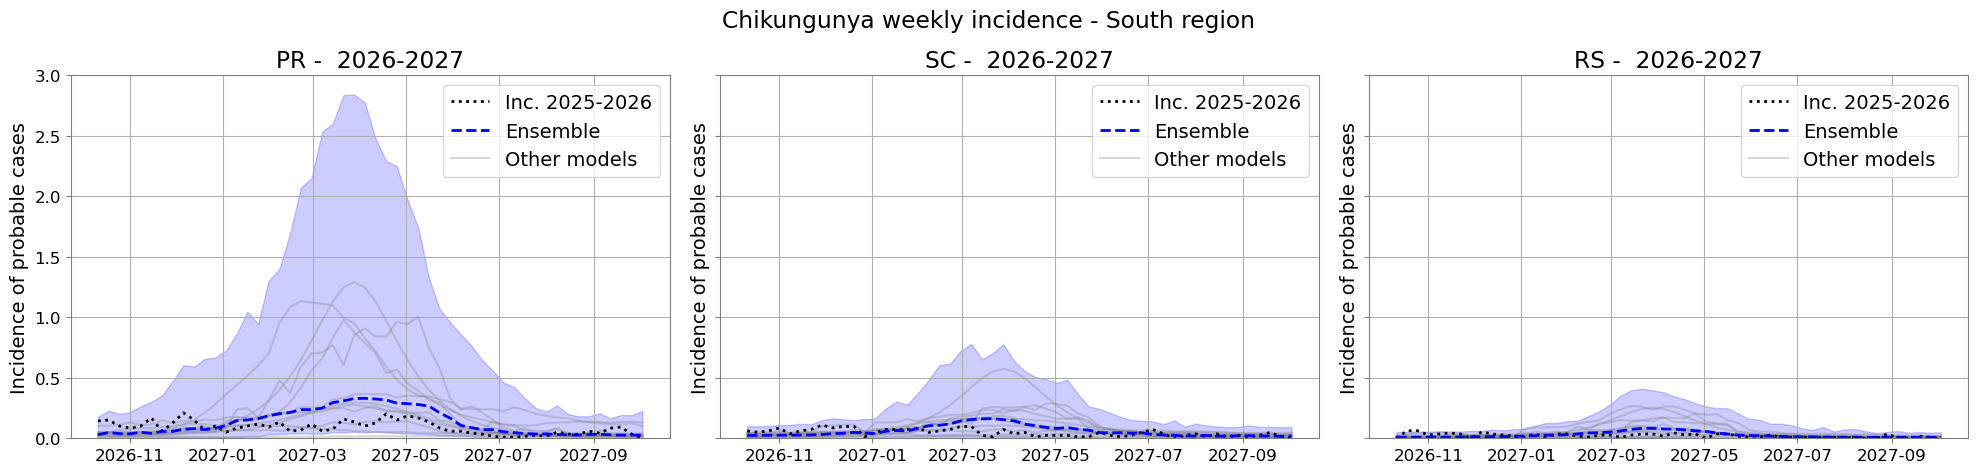

In [10]:
for language in ['en']:
    _, ax = plt.subplots(1,3, figsize = (20, 5), sharey = True)

    for state, ax_ in zip([41,42,43], ax.ravel()):
        
        #best_model = df_bm.loc[df_bm.state == state]['best_model_norm'].values[0]
        best_model = None
        make_comp_plot(ax_, state, best_model, df_median_ens, df_for, cumulative=False, language=language)

    if challenge == 'chik_state': 
        ax[0].set_ybound([0, 3])
    elif challenge == 'dengue_state': 
        ax[0].set_ybound([0, 80])

    if language == 'pt': 
        plt.suptitle('Incidência semanal - Região Sul', y = 0.95)
    else: 
        plt.suptitle(f'{disease} weekly incidence - South region', y = 0.95)

    plt.tight_layout()
    plt.savefig(f'figures/weekly_cases_sul_{language}_{challenge}.png', dpi = 400, bbox_inches = 'tight')
    plt.show()

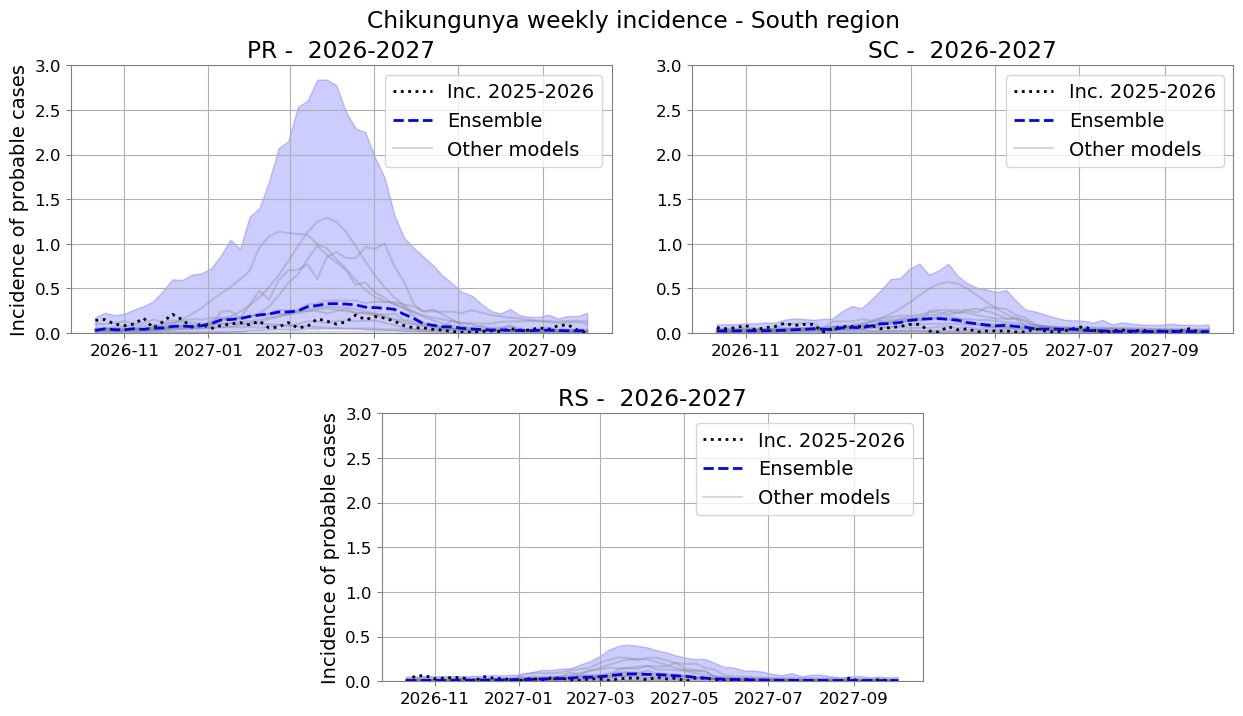

In [11]:
for language in ['en']:
    fig = plt.figure(figsize=(15, 8))

    gs = fig.add_gridspec(
        2, 4,
        hspace=0.3,
        wspace=0.35
    )

    ax1 = fig.add_subplot(gs[0, :2])  # Primeiro gráfico
    ax2 = fig.add_subplot(gs[0, 2:])  # Segundo gráfico
    ax3 = fig.add_subplot(gs[1, 1:3]) # Terceiro gráfico centralizado

    for state, ax_ in zip([41,42,43], [ax1, ax2, ax3]):
        
        #best_model = df_bm.loc[df_bm.state == state]['best_model_norm'].values[0]
        best_model = None
        make_comp_plot(ax_, state, best_model, df_median_ens, df_for, cumulative=False, language=language)

        if challenge == 'chik_state': 
            ax_.set_ybound([0, 3])
        elif challenge == 'dengue_state': 
            ax_.set_ybound([0, 80])
    ax2.set_ylabel('')
    if language == 'pt': 
        plt.suptitle('Incidência semanal - Região Sul', y = 0.95)
    else: 
        plt.suptitle(f'{disease} weekly incidence - South region', y = 0.95)

    #plt.tight_layout()
    plt.savefig(f'figures/weekly_cases_sul_{language}_{challenge}_plot.png', dpi = 400, bbox_inches = 'tight')
    plt.show()

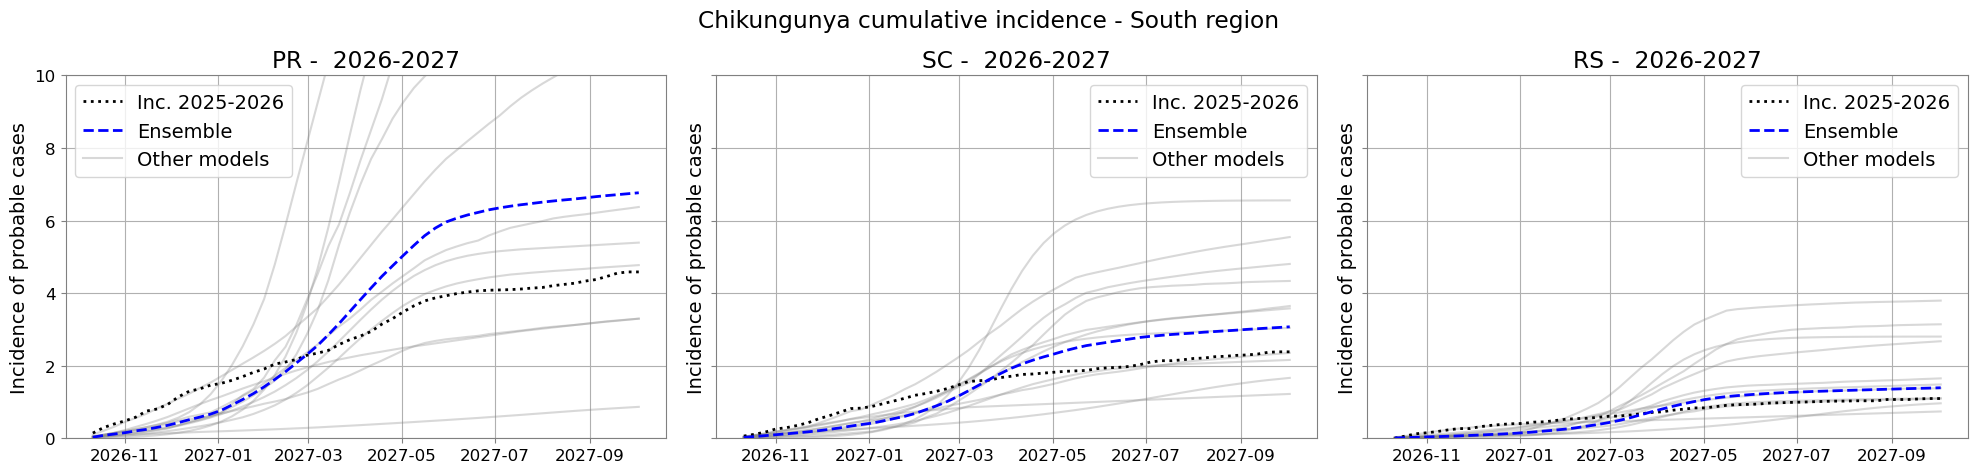

In [12]:
for language in ['en']:

    _, ax = plt.subplots(1,3, figsize = (20, 5), sharey = True)

    for state, ax_ in zip([41, 42, 43], ax.ravel()):
        
        #best_model = df_bm.loc[df_bm.state == state]['best_model_norm'].values[0]
        #best_model = 133
        make_comp_plot(ax_, state, best_model, df_median_ens, df_for, cumulative=True, language=language)

    if challenge == 'chik_state': 
        ax[0].set_ybound([0, 10])
    elif challenge == 'dengue_state': 
        ax[0].set_ybound([0, 400])


    if language == 'pt': 
        plt.suptitle('Incidência acumulada - Região Sul', y = 0.95)
    else: 
        plt.suptitle(f'{disease} cumulative incidence - South region', y = 0.95)

    plt.tight_layout()
    plt.savefig(f'figures/cumulative_cases_sul_{language}_{challenge}.png', dpi = 400, bbox_inches = 'tight')
    plt.show()

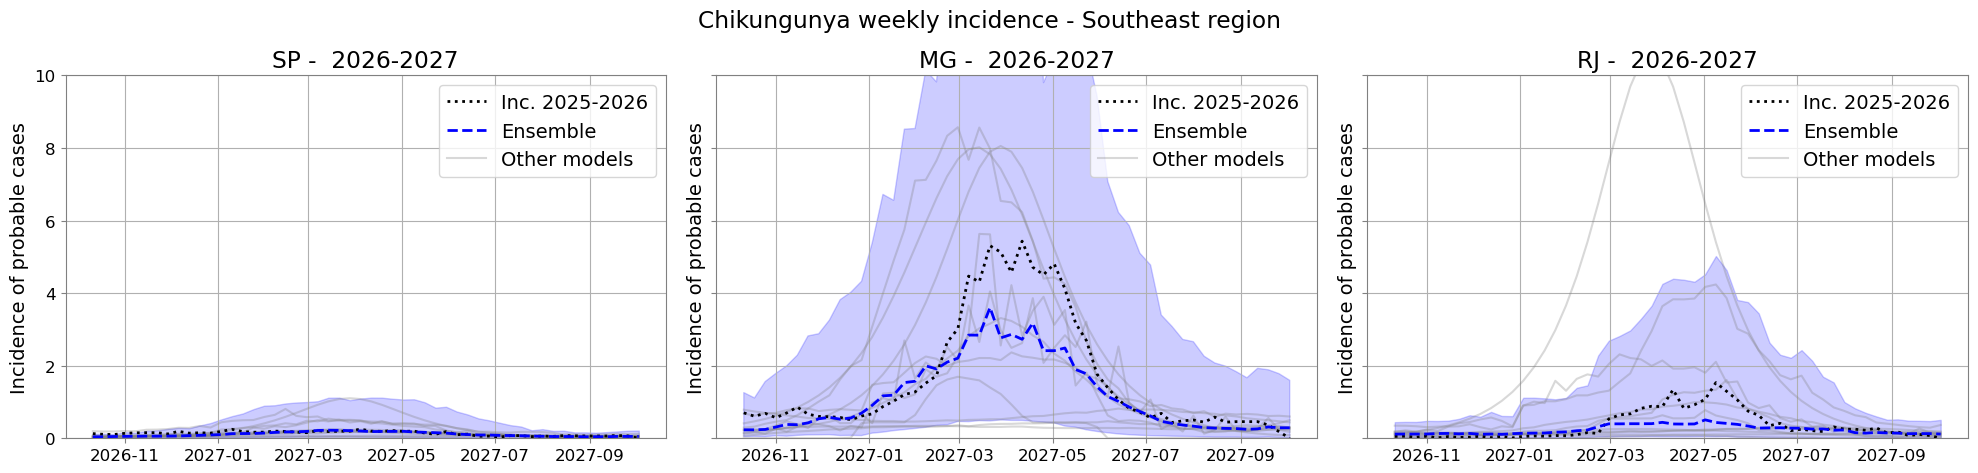

In [26]:
for language in ['en']:

    _, ax = plt.subplots(1,3, figsize = (20, 5), sharey = True)

    for state, ax_ in zip([35, 31, 33], ax.ravel()):
        
        #best_model = df_bm.loc[df_bm.state == state]['best_model_norm'].values[0]
        #if state == 'ES':
        #    best_model = 155
        best_model = None 
        make_comp_plot(ax_, state, best_model, df_median_ens, df_for, cumulative=False, language=language)

    if challenge == 'chik_state': 
        ax[0].set_ybound([0, 10])
    elif challenge == 'dengue_state': 
        ax[0].set_ybound([0, 80])

    if language == 'pt': 
        plt.suptitle('Incidência semanal - Região Sudeste', y = 0.95)
    else: 
        plt.suptitle(f'{disease} weekly incidence - Southeast region', y = 0.95)

    plt.tight_layout()
    plt.savefig(f'figures/weekly_cases_sudeste_{language}_{challenge}.png', dpi = 400, bbox_inches = 'tight')
    plt.show()
    

/tmp/ipykernel_65090/3317039299.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


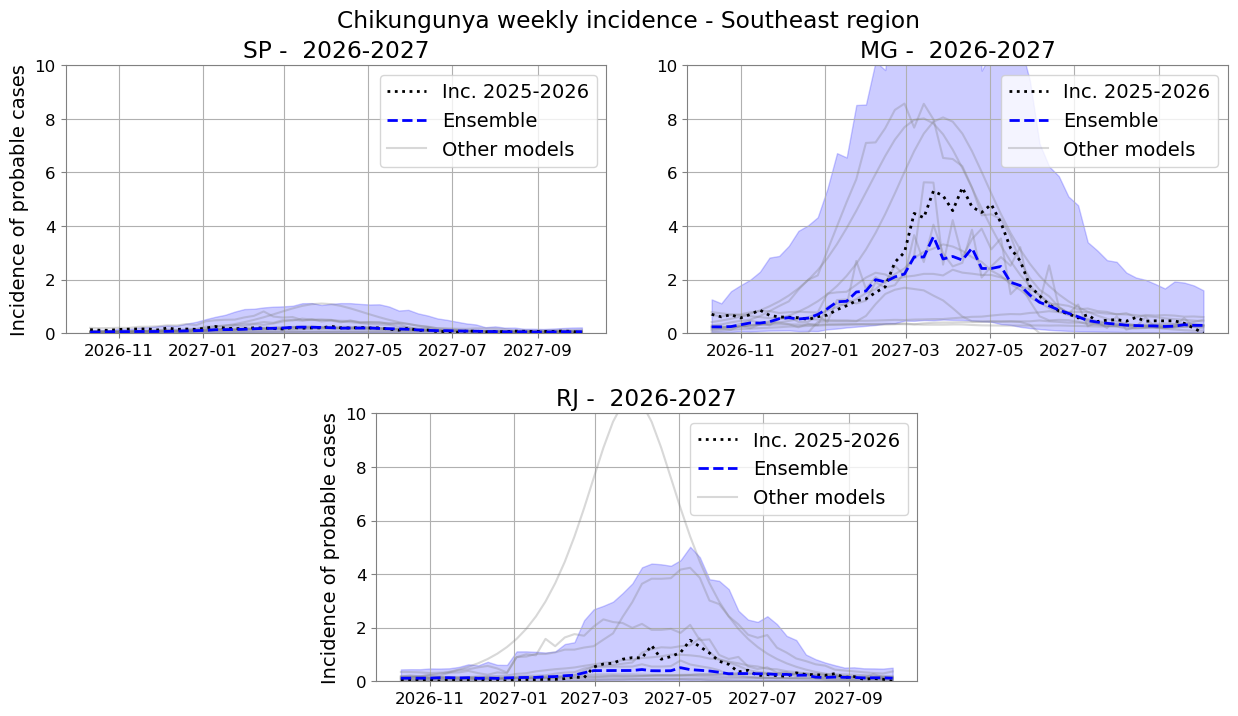

In [27]:
for language in ['en']:

    fig = plt.figure(figsize=(15, 8))

    gs = fig.add_gridspec(
        2, 4,
        hspace=0.3,
        wspace=0.35
    )

    ax1 = fig.add_subplot(gs[0, :2])  # Primeiro gráfico
    ax2 = fig.add_subplot(gs[0, 2:])  # Segundo gráfico
    ax3 = fig.add_subplot(gs[1, 1:3]) # Terceiro gráfico centralizado

    for state, ax_ in zip([35, 31, 33], [ax1,ax2,ax3]):
        
        #best_model = df_bm.loc[df_bm.state == state]['best_model_norm'].values[0]
        #if state == 'ES':
        #    best_model = 155
        best_model = None 
        make_comp_plot(ax_, state, best_model, df_median_ens, df_for, cumulative=False, language=language)

        if challenge == 'chik_state': 
            ax_.set_ybound([0, 10])
        elif challenge == 'dengue_state': 
            ax_.set_ybound([0, 80])

    ax2.set_ylabel('')

    if language == 'pt': 
        plt.suptitle('Incidência semanal - Região Sudeste', y = 0.95)
    else: 
        plt.suptitle(f'{disease} weekly incidence - Southeast region', y = 0.95)

    plt.tight_layout()
    plt.savefig(f'figures/weekly_cases_sudeste_{language}_{challenge}_plot.png', dpi = 400, bbox_inches = 'tight')
    plt.show()

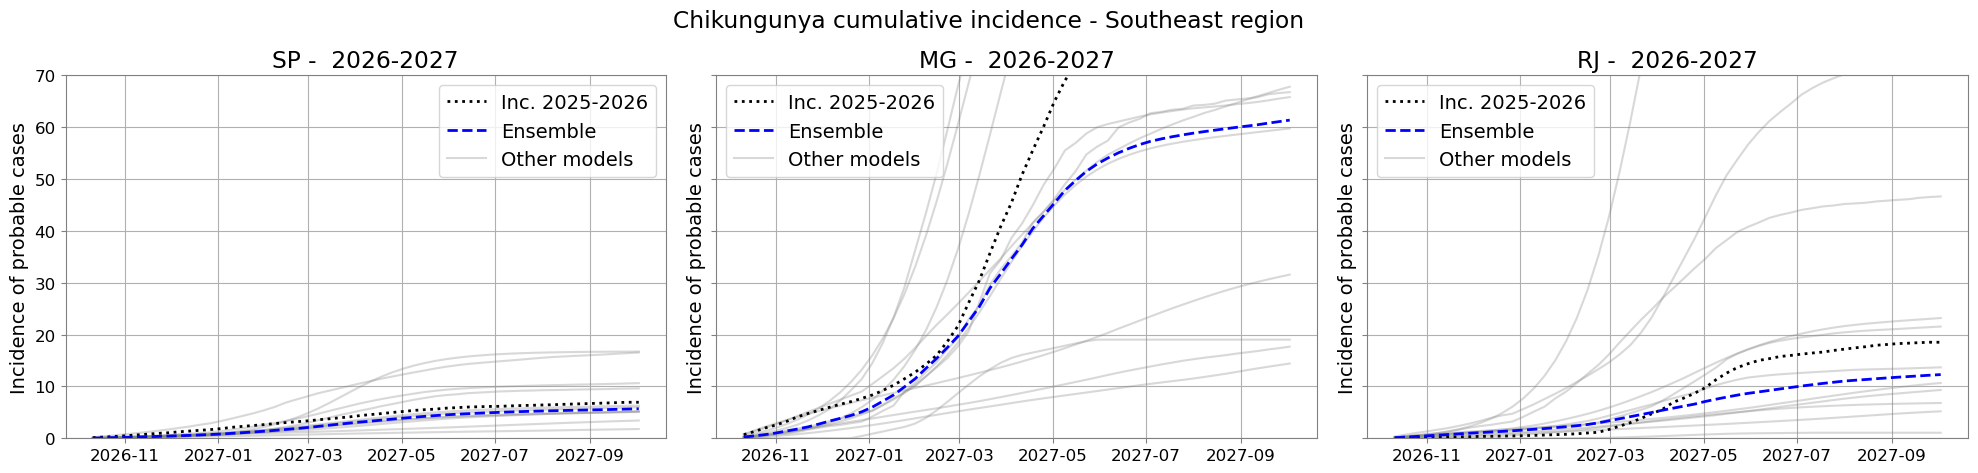

In [28]:
for language in ['en']:
 
    _, ax = plt.subplots(1,3, figsize = (20, 5), sharey = True)

    for state, ax_ in zip([35, 31, 33], ax.ravel()):
        
        #best_model = df_bm.loc[df_bm.state == state]['best_model_norm'].values[0]
        best_model = None
        make_comp_plot(ax_, state, best_model, df_median_ens, df_for, cumulative=True, language=language)

    if challenge == 'chik_state': 
        ax[0].set_ybound([0, 70])
    elif challenge == 'dengue_state': 
        ax[0].set_ybound([0, 1000])

    if language == 'pt': 
        plt.suptitle('Incidência acumulada - Região Sudeste', y = 0.95)
    else: 
        plt.suptitle(f'{disease} cumulative incidence - Southeast region', y = 0.95)
    
    plt.tight_layout()
    plt.savefig(f'figures/cumulative_cases_sudeste_{language}_{challenge}.png', dpi = 400, bbox_inches = 'tight')
    plt.show()

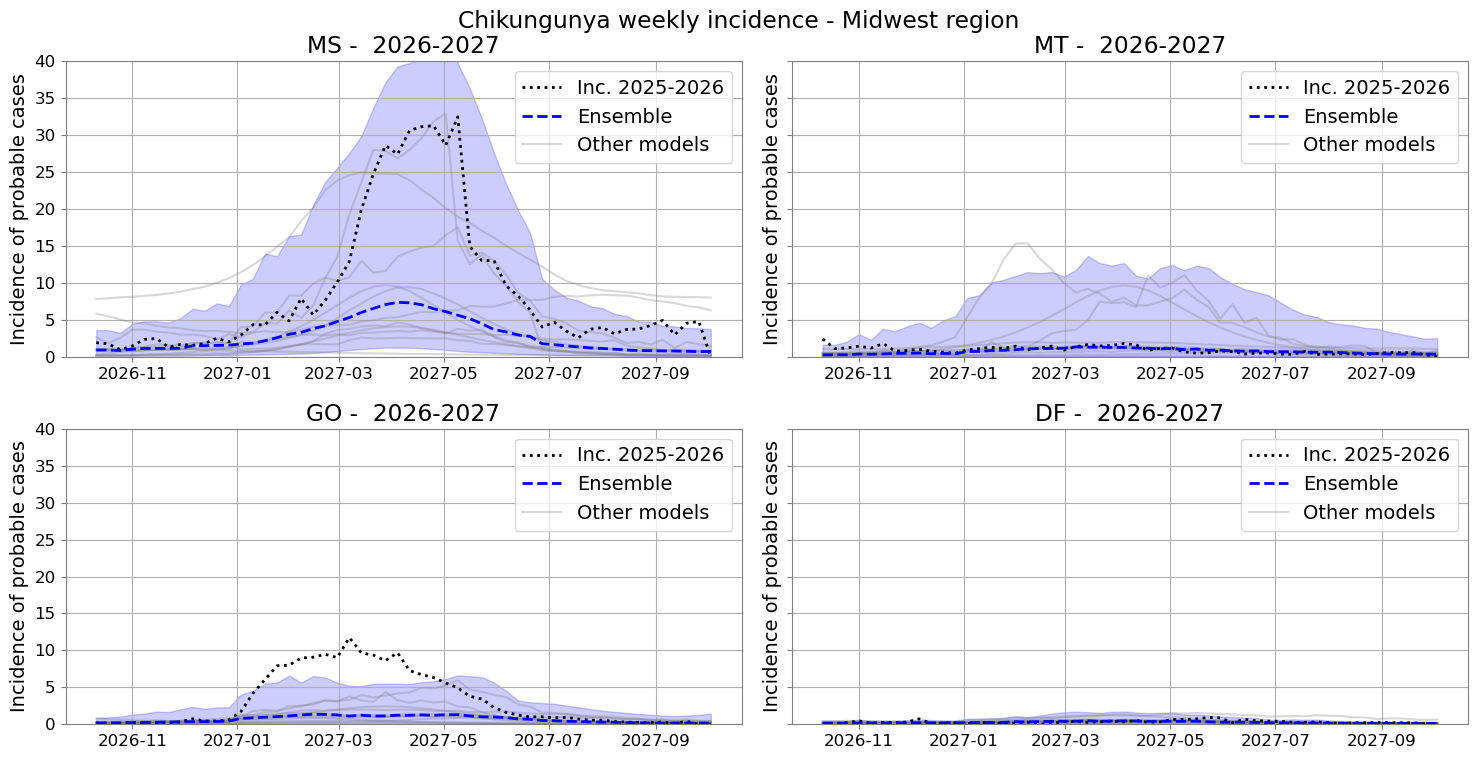

In [29]:
for language in ['en']:
 
    _, ax = plt.subplots(2,2, figsize = (15, 8), sharey = True)

    for state, ax_ in zip([50, 51, 52, 53], ax.ravel()):
        
        #best_model = df_bm.loc[df_bm.state == state]['best_model_norm'].values[0]
        best_model = None 
        make_comp_plot(ax_, state, best_model, df_median_ens, df_for, cumulative=False, language=language)

    if challenge == 'chik_state': 
        ax[0,0].set_ybound([0, 40])
    elif challenge == 'dengue_state': 
        ax[0,0].set_ybound([0, 200])

    if language == 'pt': 
        plt.suptitle('Incidência semanal - Região Centro-Oeste', y = 0.95)
    else: 
        plt.suptitle(f'{disease} weekly incidence - Midwest region', y = 0.95)

    plt.tight_layout()
    plt.savefig(f'figures/weekly_cases_centro_oeste_{language}_{challenge}.png', dpi = 400, bbox_inches = 'tight')
    plt.show()

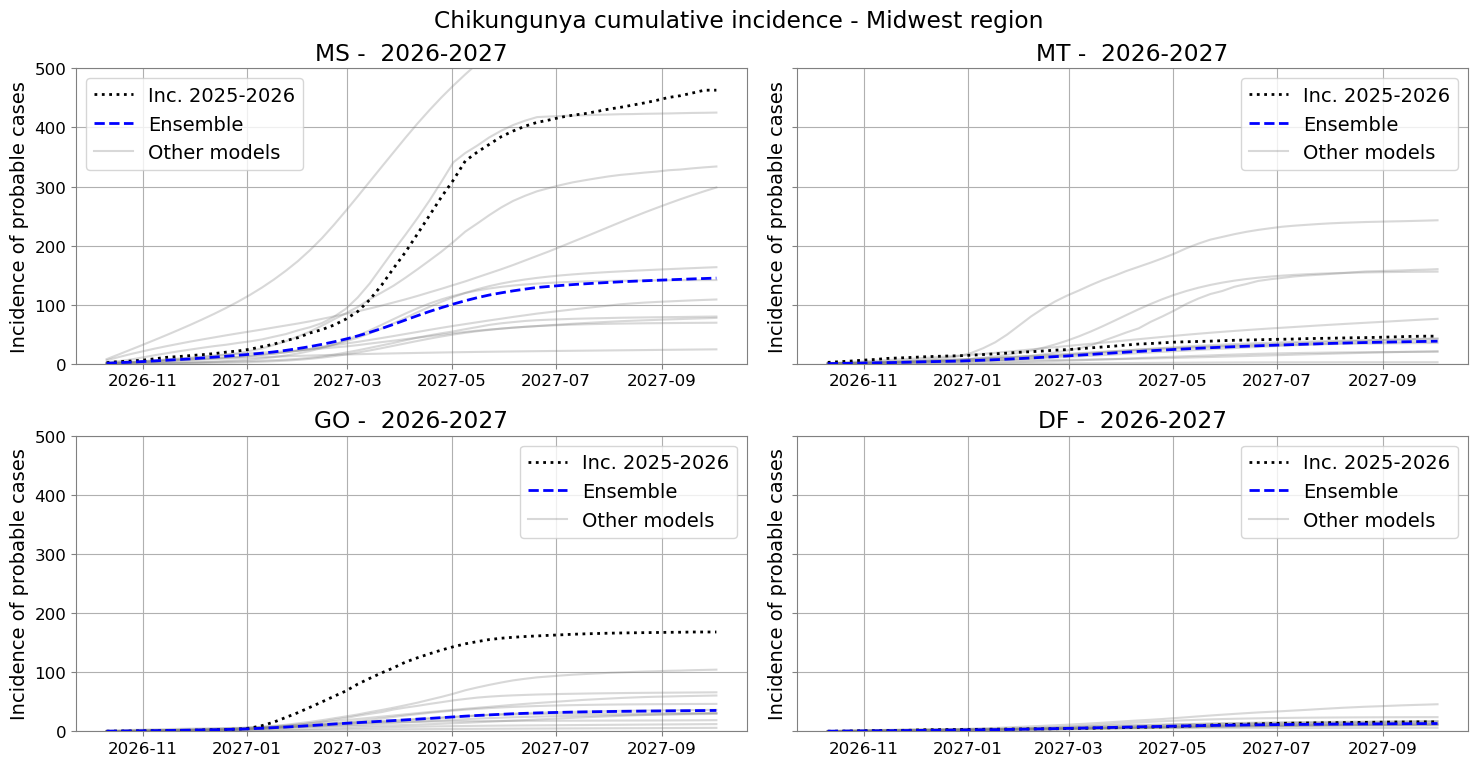

In [30]:
for language in ['en']:

    _, ax = plt.subplots(2,2, figsize = (15, 8), sharey = True)

    for state, ax_ in zip([50, 51, 52, 53], ax.ravel()):
        
        #best_model = df_bm.loc[df_bm.state == state]['best_model_norm'].values[0]
        best_model = None
        make_comp_plot(ax_, state, best_model, df_median_ens, df_for, cumulative=True, language=language)

    if challenge == 'chik_state': 
        ax[0,0].set_ybound([0, 500])
    elif challenge == 'dengue_state': 
        ax[0,0].set_ybound([0, 2000])

    if language == 'pt': 
        plt.suptitle('Incidência acumulada - Região Centro - Oeste', y = 0.95)
    else: 
        plt.suptitle(f'{disease} cumulative incidence - Midwest region', y = 0.96)
    
    plt.tight_layout()
    plt.savefig(f'figures/cumulative_cases_centro_oeste_{language}_{challenge}.png', dpi = 400, bbox_inches = 'tight')
    plt.show()

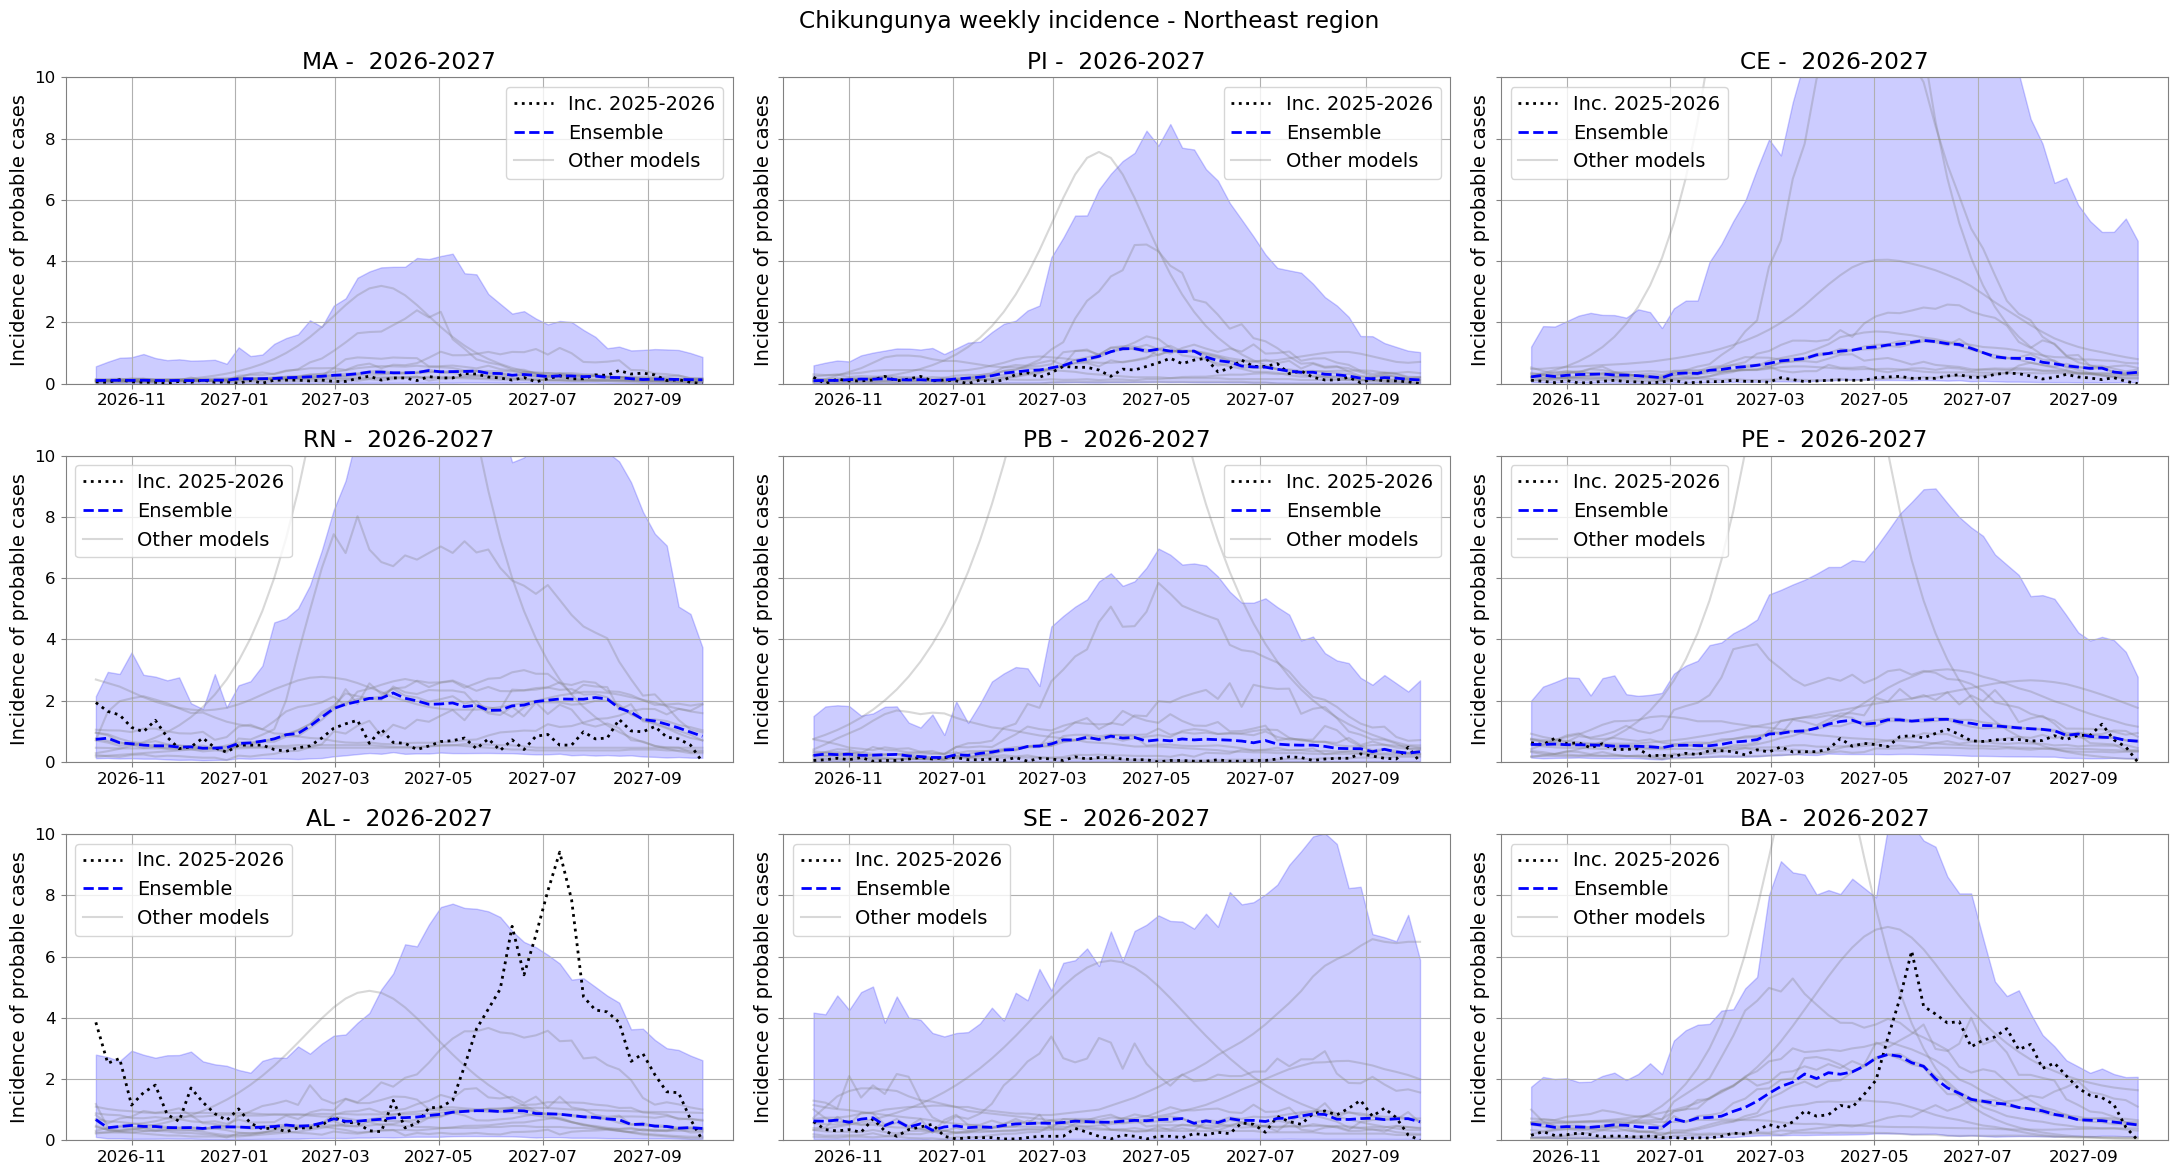

In [31]:
for language in ['en']:
    
    _, ax = plt.subplots(3,3, figsize = (22, 12), sharey = True)

    for state, ax_ in zip(np.arange(21,30), ax.ravel()):
        
        #best_model = df_bm.loc[df_bm.state == state]['best_model_norm'].values[0]
        best_model = None
        make_comp_plot(ax_, state, best_model, df_median_ens, df_for, cumulative=False, language=language)


    if challenge == 'chik_state': 
        ax[0,0].set_ybound([0, 10])
    elif challenge == 'dengue_state': 
        ax[0,0].set_ybound([0, 40])

    

    if language == 'pt': 
        plt.suptitle('Incidência semanal - Região Nordeste', y = 0.98)
    else: 
        plt.suptitle(f'{disease} weekly incidence - Northeast region', y = 0.98)


    plt.tight_layout()
    plt.savefig(f'figures/weekly_cases_nordeste_{language}_{challenge}.png', dpi = 400, bbox_inches = 'tight')
    plt.show()

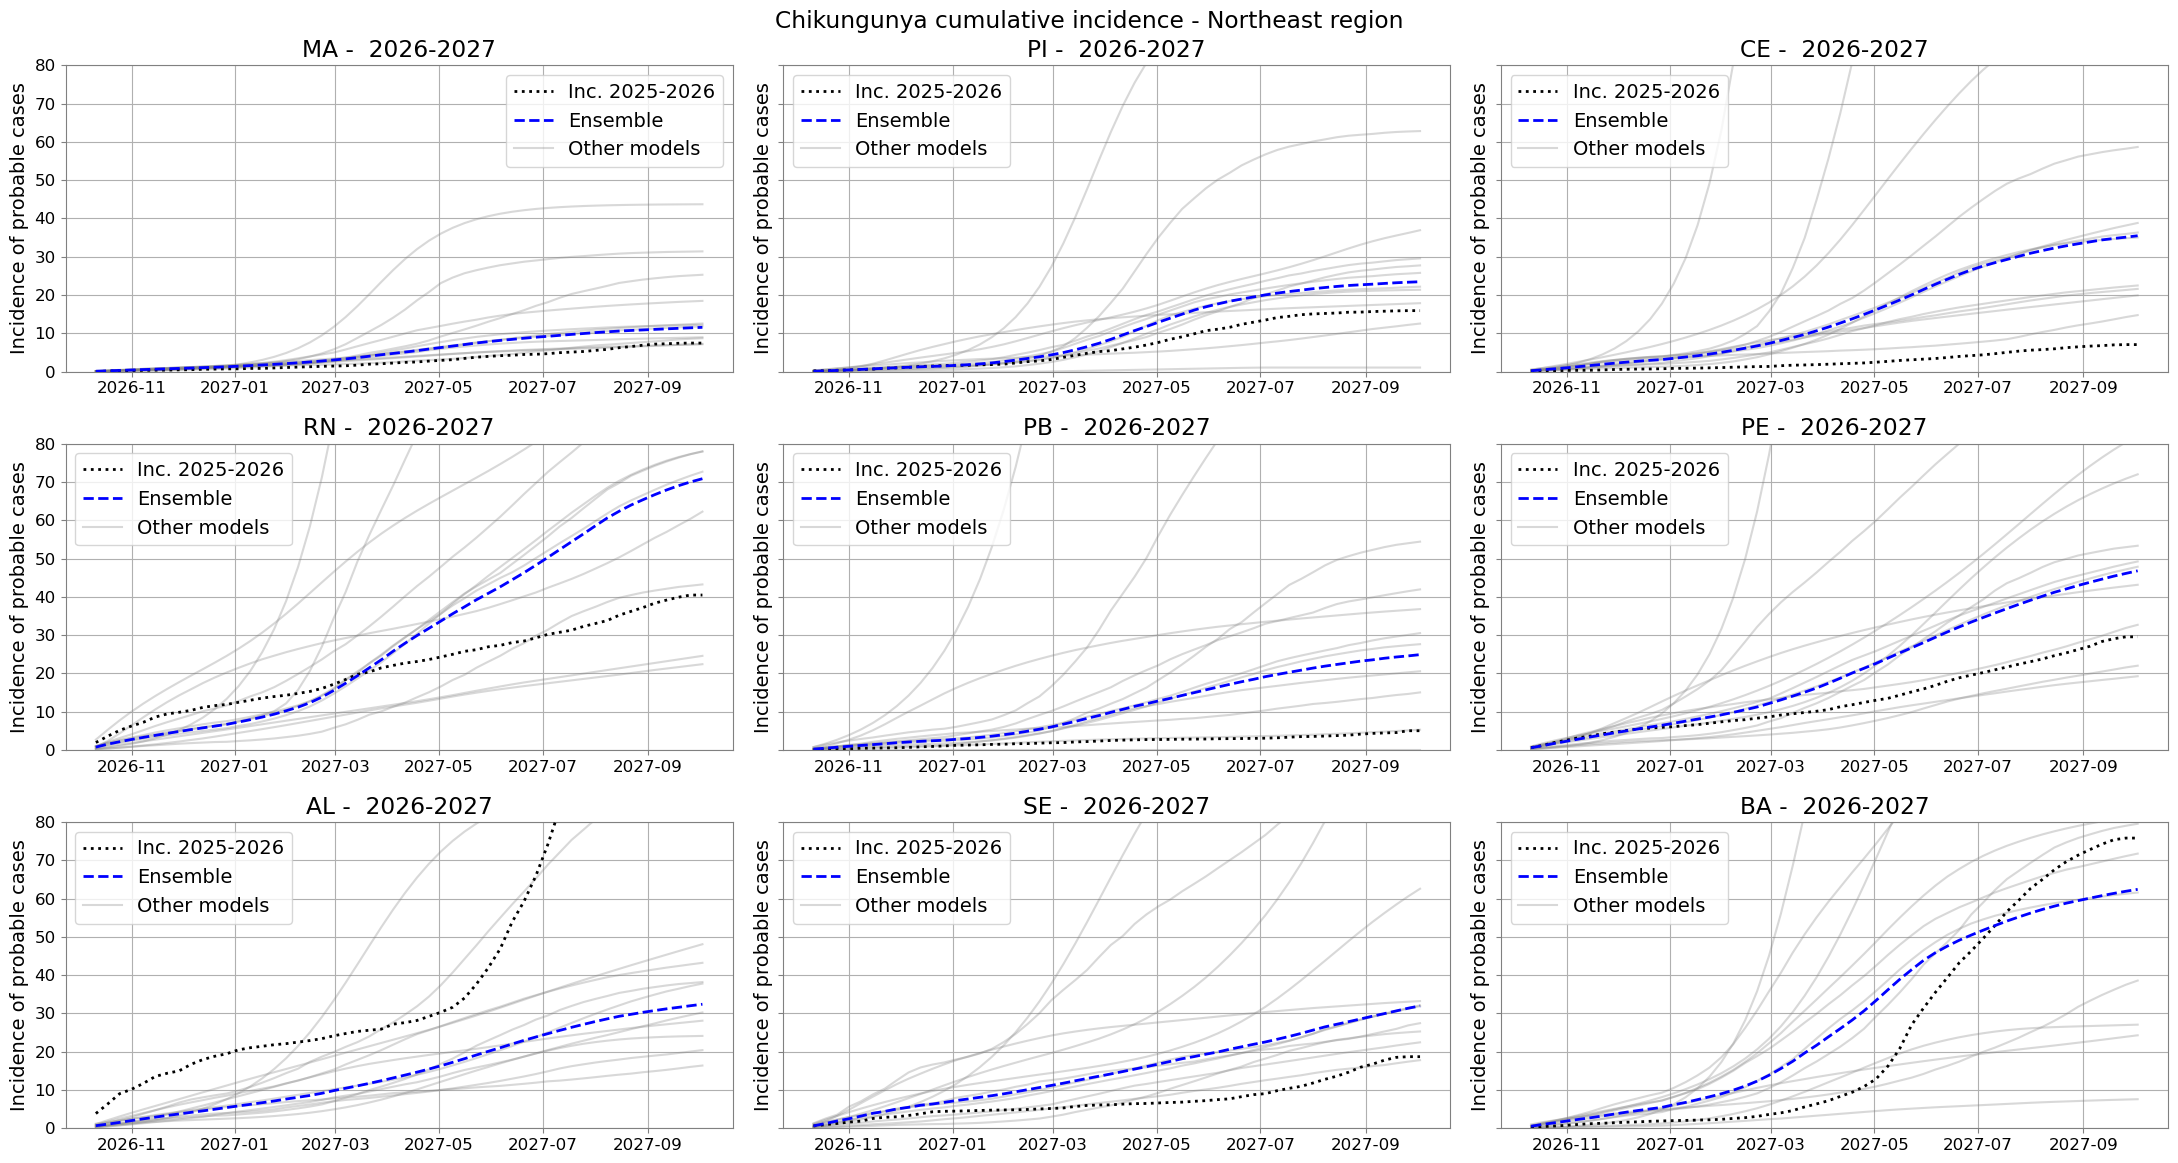

In [32]:
for language in ['en']:
    
    _, ax = plt.subplots(3,3, figsize = (22, 12), sharey = True)

    for state, ax_ in zip(np.arange(21,30), ax.ravel()):
        
        #best_model = df_bm.loc[df_bm.state == state]['best_model_norm'].values[0]
        best_model = None 
        make_comp_plot(ax_, state, best_model, df_median_ens, df_for, cumulative=True, language=language)

    if challenge == 'chik_state': 
        ax[0,0].set_ybound([0, 80])
    elif challenge == 'dengue_state': 
        ax[0,0].set_ybound([0, 600])

    if language == 'pt': 
        plt.suptitle('Incidência acumulada - Região Nordeste', y = 0.97)
    else: 
        plt.suptitle(f'{disease} cumulative incidence - Northeast region', y = 0.97)
    
    plt.tight_layout()
    plt.savefig(f'figures/cumulative_cases_nordeste_{language}_{challenge}.png', dpi = 400, bbox_inches = 'tight')
    plt.show()

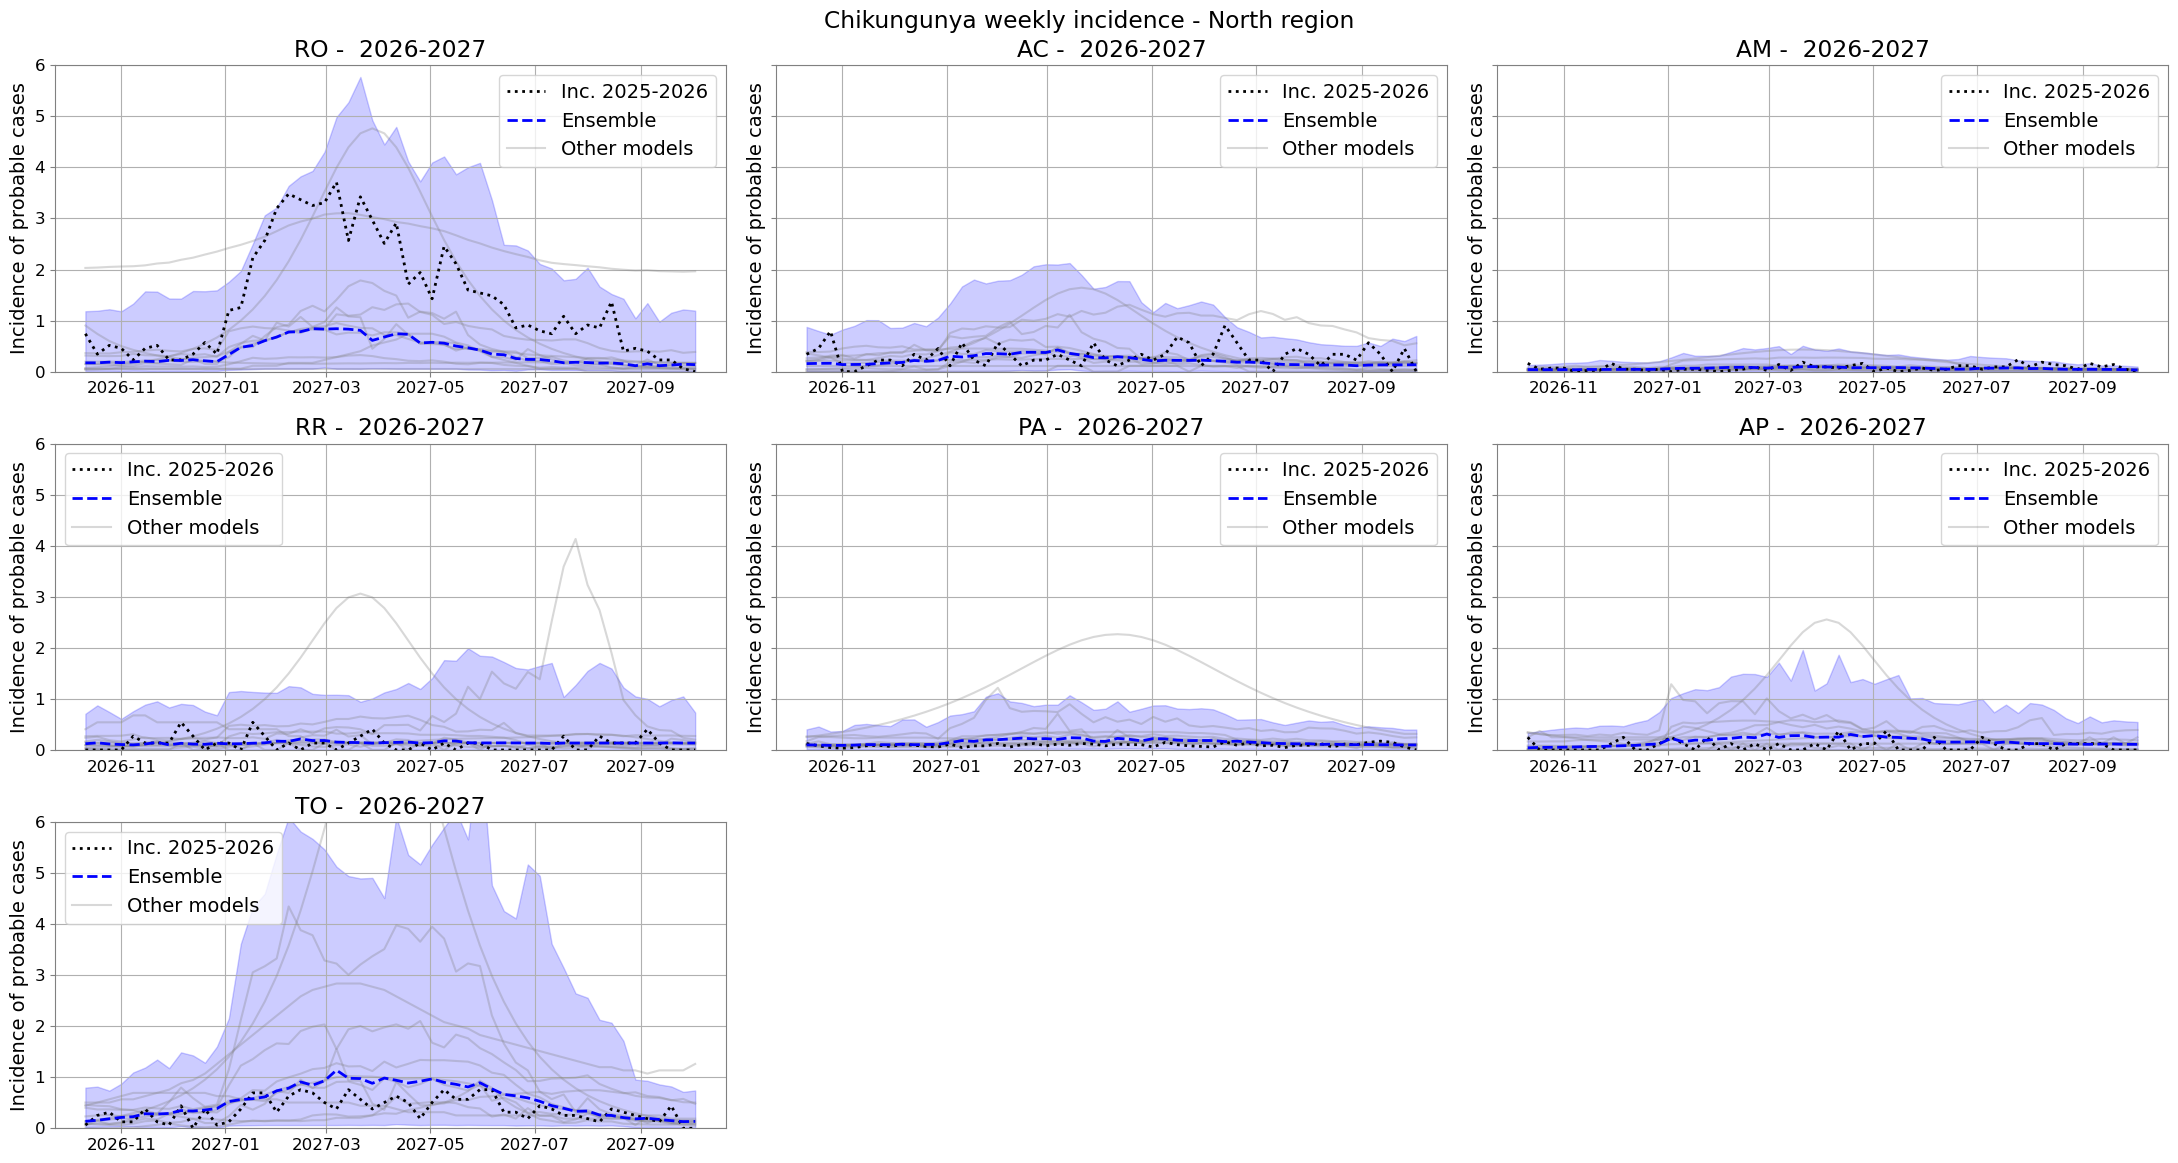

In [33]:
for language in ['en']:

    _, ax = plt.subplots(3,3, figsize = (22, 12), sharey = True)

    for state, ax_ in zip(np.arange(11,18), ax.ravel()):
        
        #best_model = df_bm.loc[df_bm.state == state]['best_model_norm'].values[0]
        best_model = None 
        make_comp_plot(ax_, state, best_model, df_median_ens, df_for, cumulative=False, language=language)

    ax[0,0].set_ybound([0, 10])

    if challenge == 'chik_state': 
        ax[0,0].set_ybound([0, 6])
    elif challenge == 'dengue_state': 
        ax[0,0].set_ybound([0, 80])
    
    ax[2,1].axis('off')
    ax[2,2].axis('off')
    
    if language == 'pt': 
        plt.suptitle('Incidência semanal - Região Norte', y = 0.97)
    else: 
        plt.suptitle(f'{disease} weekly incidence - North region', y = 0.97)

    plt.tight_layout()
    plt.savefig(f'figures/weekly_cases_norte_{language}_{challenge}.png', dpi = 400, bbox_inches = 'tight')
    plt.show()

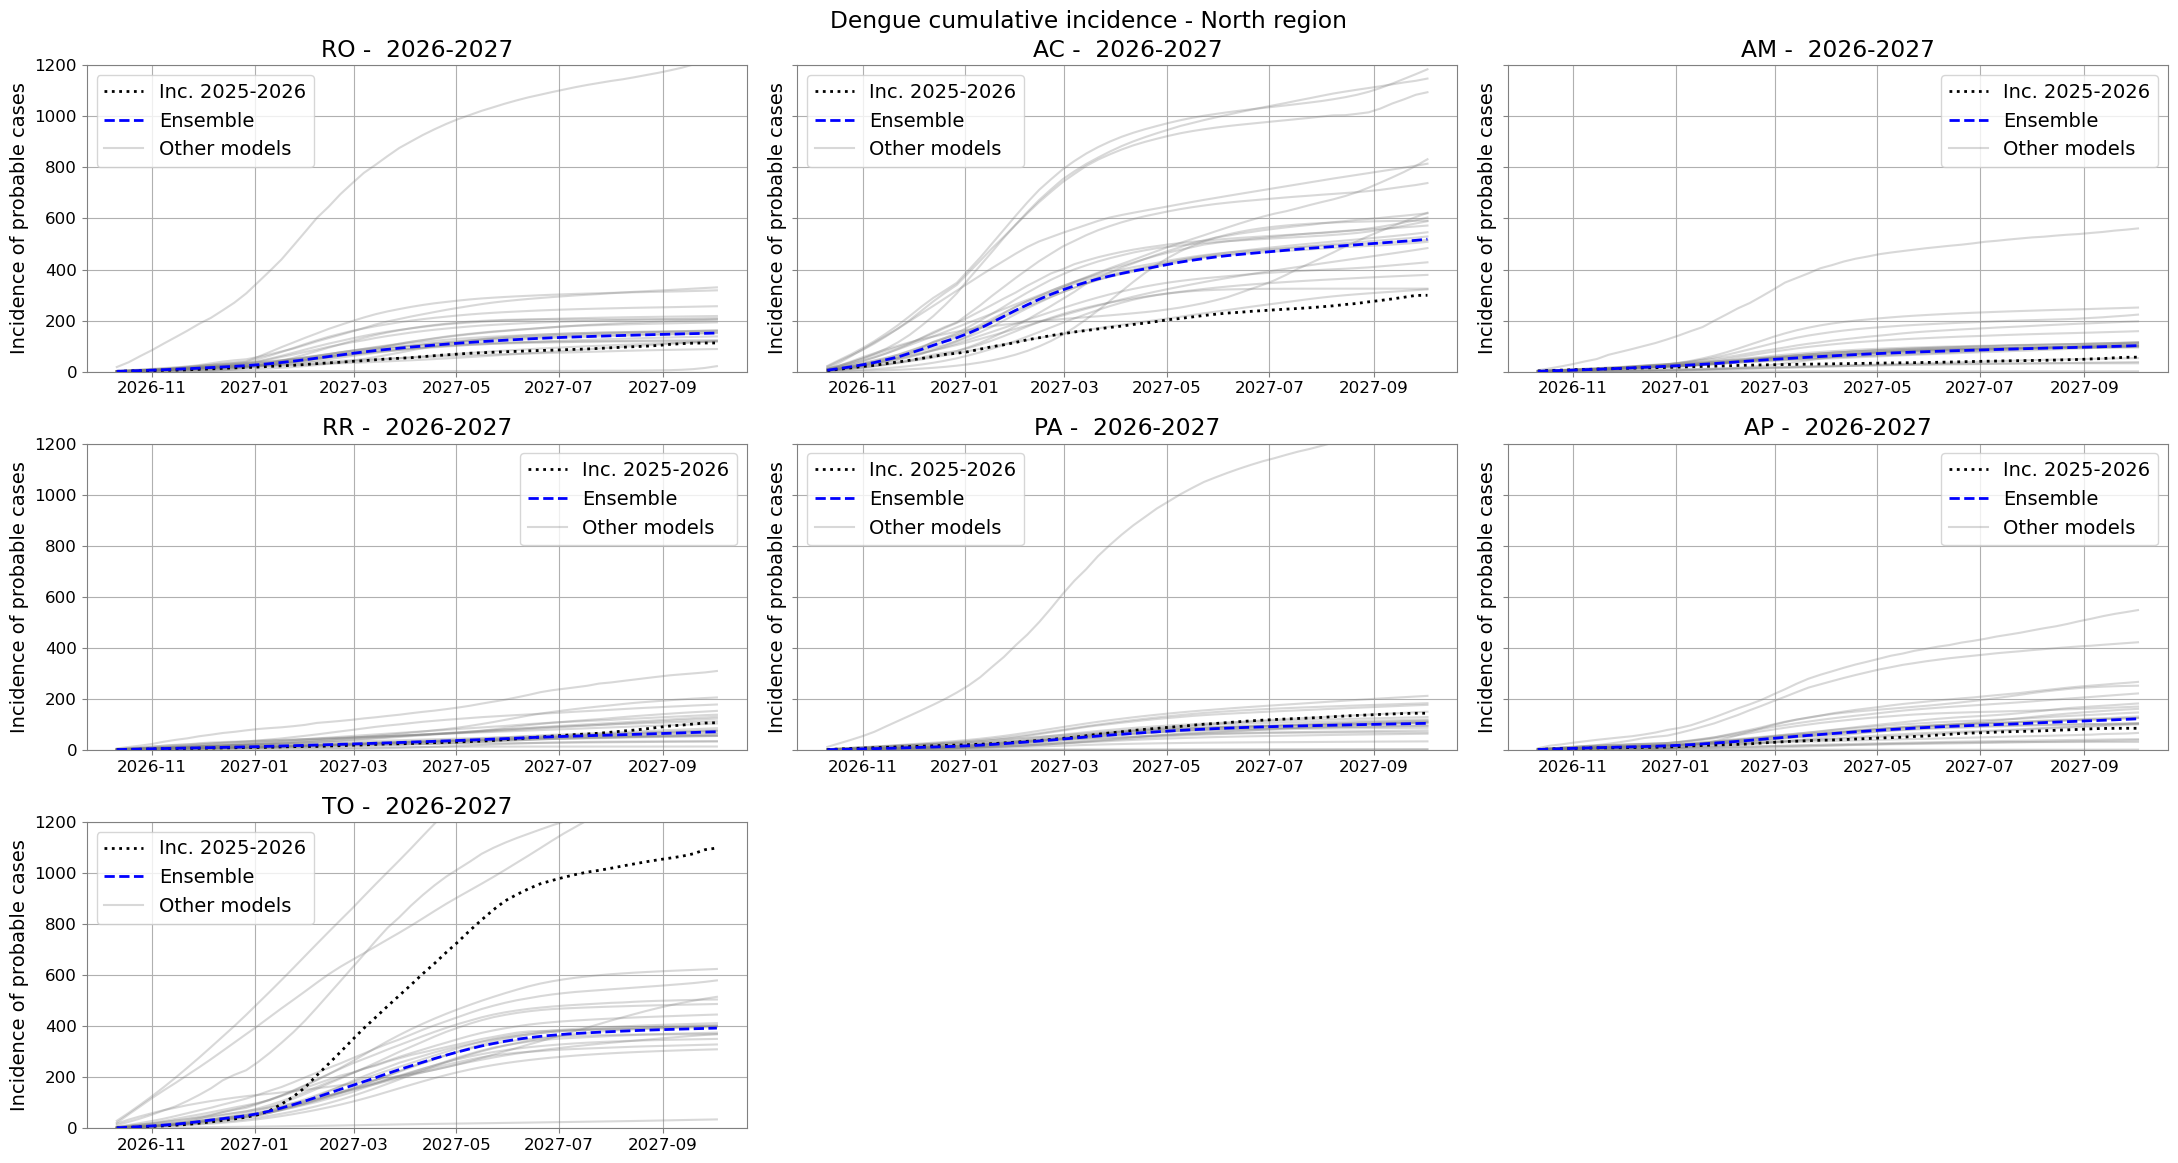

In [12]:
for language in ['en']:

    _, ax = plt.subplots(3,3, figsize = (22, 12), sharey = True)

    for state, ax_ in zip(np.arange(11,18), ax.ravel()):
        
        #best_model = df_bm.loc[df_bm.state == state]['best_model_norm'].values[0]
        best_model = None
        make_comp_plot(ax_, state, best_model, df_median_ens, df_for, cumulative=True, language=language)

    if challenge == 'chik_state': 
        ax[0,0].set_ybound([0, 80])
    elif challenge == 'dengue_state': 
        ax[0,0].set_ybound([0, 1200])
        
    ax[2,1].axis('off')
    ax[2,2].axis('off')

    if language == 'pt': 
        plt.suptitle('Incidência acumulada - Região Norte', y = 0.97)
    else: 
        plt.suptitle(f'{disease} cumulative incidence - North region', y = 0.97)
    

    plt.tight_layout()
    plt.savefig(f'figures/cumulative_cases_norte_{language}_{challenge}.png', dpi = 400, bbox_inches = 'tight')
    plt.show()

Gráfico dos casos acumulados por para o país:

In [35]:
df_cum_cop = pd.read_csv(f'predictions/preds_ensemble_2026_cum_cases_{challenge}.csv.gz')
df_cum_cop = df_cum_cop.merge(df_pop, on = 'adm_1')
for col in ['lower_90', 'pred', 'upper_90']:

    df_cum_cop[f'inc_{col}'] = 100000*df_cum_cop[col]/df_cum_cop['population']

df_cum_cop['adm_1'] = df_cum_cop['adm_1'].replace(code_to_state)
df_cum_cop.head()

,model,validation,adm_1,lower_90,pred,upper_90,population,inc_lower_90,inc_pred,inc_upper_90
0,ensemble,Forecast,AC,76.883098,158.878725,396.910270,884372,8.693525,17.965146,44.880466
1,ensemble,Forecast,AL,592.270393,1674.473300,5317.670913,3220848,18.388648,51.988585,165.101579
2,ensemble,Forecast,AM,109.265234,192.582758,383.759215,4321616,2.528342,4.456267,8.879993
3,ensemble,Forecast,AP,59.375051,129.123079,388.597498,806517,7.361909,16.009964,48.182183
4,ensemble,Forecast,BA,2404.571198,8762.198472,37368.241629,14870907,16.169634,58.921749,251.284213


In [36]:
order = [
    # Sul
    'PR', 'RS', 'SC',
    # Sudeste
    'ES', 'MG', 'RJ', 'SP',
    # Centro-Oeste
    'DF', 'GO', 'MT', 'MS',
    # Nordeste
    'AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE',
    # Norte
    'AC', 'AM', 'AP', 'PA', 'RO', 'RR', 'TO' ]

In [37]:
df_inc['adm_1'] = df_inc['adm_1'].replace(code_to_state)

df_inc.head()

,adm_1,casprov_2026,population,inc
0,RO,1271,1751950,72.547733
1,AC,138,884372,15.604293
2,AM,166,4321616,3.841156
3,RR,44,738772,5.955829
4,PA,418,8711196,4.798423


In [38]:
df_inc['adm_1'] = pd.Categorical(df_inc['adm_1'],
                                     categories = order,
                                     ordered = True)

df_inc = df_inc.sort_values(by = 'adm_1')

df_inc = df_inc.loc[df_inc.adm_1 != 'ES']

df_inc.head()

,adm_1,casprov_2026,population,inc
20,PR,545,11890517,4.583484
22,RS,123,11233263,1.094962
21,SC,195,8187029,2.381816
16,MG,18547,21393441,86.694796
18,RJ,3190,17223547,18.521156


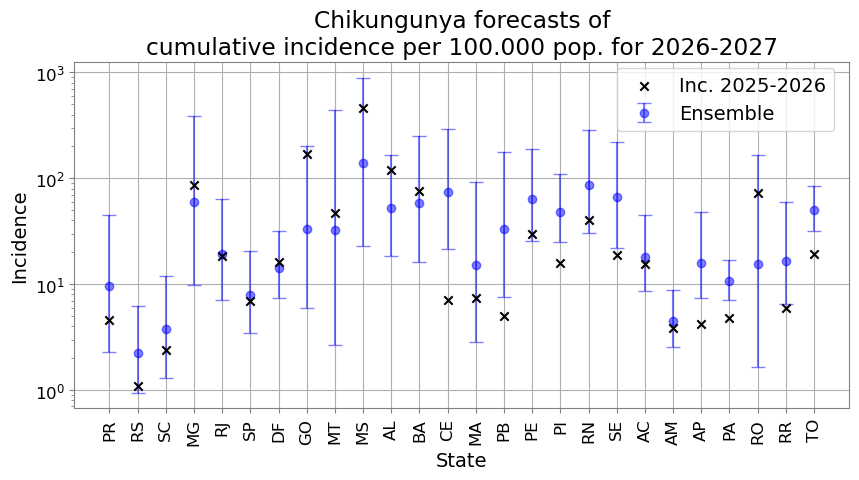

In [41]:
_, ax = plt.subplots(figsize = (10, 4.5))

#ax.axhline(obs, color = 'black', linewidth =2, linestyle = '--', label = 'Data')
ax.scatter(df_inc.adm_1, df_inc.inc, marker = 'x',color = 'black', label = 'Inc. 2025-2026', zorder = 3)

#x = df_cum_best_models.state.astype(str)
#y = df_cum_best_models.inc_pred
    
# compute symmetric errors from lower and upper bounds
#yerr = np.array([y - df_cum_best_models.inc_lower_90, df_cum_best_models.inc_upper_90 - y])

#for xi, yi, yierr, low, up in zip(x, y, yerr.T, df_cum_best_models.inc_lower_90, df_cum_best_models.inc_upper_90):
    # condition: observed is inside prediction interval

#    ax.errorbar(xi, yi, yerr=yierr.reshape(2,1), fmt="o", 
#                    color='red', ecolor='red', capsize=5, alpha = 0.5, label ='Best model')


# método da cópula
x = df_cum_cop.adm_1.astype(str)
y = df_cum_cop.inc_pred
    
# compute symmetric errors from lower and upper bounds
yerr = np.array([y - df_cum_cop.inc_lower_90, df_cum_cop.inc_upper_90 - y])

for xi, yi, yierr, low, up in zip(x, y, yerr.T, df_cum_cop.inc_lower_90, df_cum_cop.inc_upper_90):
    # condition: observed is inside prediction interval

    ax.errorbar(xi, yi, yerr=yierr.reshape(2,1), fmt="o", 
                    color='blue', ecolor='blue', capsize=5, alpha = 0.5, label = 'Ensemble')

language = 'en'

if language == 'pt':
    ax.set_ylabel('Incidência')
    ax.set_xlabel('Estados')
        
    ax.set_title(f'Previsão da incidência acumulada por 100.000hab em 2026-2027')

elif language == 'en': 
    ax.set_ylabel('Incidence')
    ax.set_xlabel('State')
        
    ax.set_title(f'{disease} forecasts of\ncumulative incidence per 100.000 pop. for 2026-2027')
   

#    ax.set_ylim([0, max(2*df_cum_cases.loc[(df_cum_cases.state == state) & (df_cum_cases.valid_test == 1)].casos.values[0],
#                        2*df_cum_cases.loc[(df_cum_cases.state == state) & (df_cum_cases.valid_test == 2)].casos.values[0], 
#                        2*df_cum_cases.loc[(df_cum_cases.state == state) & (df_cum_cases.valid_test == 3)].casos.values[0])])
#ax.set_yscale('log')
ax.grid()
ax.legend()
for label in ax.get_xticklabels():
        label.set_rotation(90)

ax.set_yscale('log')

handles, labels = plt.gca().get_legend_handles_labels()

# Remove duplicates
unique = dict(zip(labels, handles))

#plt.legend(unique.values(), unique.keys(), loc =(0.7,0.08))
plt.legend(unique.values(), unique.keys(), loc =(0.7,0.8))

plt.savefig(f'figures/cum_inc_2027_{language}_{challenge}_log.png', dpi = 400, bbox_inches = 'tight')
plt.show()


### Make a map:

In [42]:
import geopandas as gpd 
import matplotlib.colors as colors
from shapely.geometry import Polygon, MultiPolygon


In [43]:
def remove_holes(geom):
    if geom.geom_type == "Polygon":
        return Polygon(geom.exterior)  # mantém só o contorno externo
    elif geom.geom_type == "MultiPolygon":
        # acessa cada polígono dentro do MultiPolygon
        return MultiPolygon([Polygon(p.exterior) for p in geom.geoms])
    else:
        return geom
    

df_muni = gpd.read_file('../imdc_2026/data/shape_muni.gpkg')

df_muni["geometry"] = df_muni.buffer(0)

df_uf = df_muni.dissolve(by="uf")

df_uf["geometry"] = df_uf["geometry"].apply(remove_holes)

df_uf["geometry"] = df_uf.buffer(1e-9).buffer(-1e-9)

# reset index if you want 'uf' back as a column
df_uf = df_uf.reset_index()

df_uf_m = df_uf.merge(df_cum_cop[['adm_1', 'lower_90', 'pred', 'upper_90',
            'inc_lower_90', 'inc_pred', 'inc_upper_90']].merge(df_inc, on = 'adm_1', suffixes=('_ens', 'data')), left_on = 'uf', right_on = 'adm_1')

df_uf_m['diff_casos'] =   df_uf_m['pred'] -  df_uf_m['casprov_2026']
df_uf_m['diff_inc'] =  df_uf_m['inc_pred'] - df_uf_m['inc']
df_uf_m['ratio_inc'] =  100*df_uf_m['inc_pred']/df_uf_m['inc']

df_uf_m.head()

/tmp/ipykernel_65090/1758777030.py:19: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  df_uf["geometry"] = df_uf.buffer(1e-9).buffer(-1e-9)


,uf,geometry,geocode,geocode_name,uf_code,adm_1,lower_90,pred,upper_90,inc_lower_90,inc_pred,inc_upper_90,casprov_2026,population,inc,diff_casos,diff_inc,ratio_inc
0,AC,"POLYGON ((-70.51515 -7.79238, -70.05498 -7.845...",1200013,Acrelândia,12,AC,76.883098,158.878725,396.910270,8.693525,17.965146,44.880466,138,884372,15.604293,20.878725,2.360853,115.129511
1,AL,"MULTIPOLYGON (((-38.23759 -9.3298, -38.23759 -...",2700102,Água Branca,27,AL,592.270393,1674.473300,5317.670913,18.388648,51.988585,165.101579,3856,3220848,119.720024,-2181.526700,-67.731439,43.425137
2,AM,"POLYGON ((-72.37321 -4.83344, -72.37321 -4.833...",1300029,Alvarães,13,AM,109.265234,192.582758,383.759215,2.528342,4.456267,8.879993,166,4321616,3.841156,26.582758,0.615112,116.013709
3,AP,"MULTIPOLYGON (((-54.87625 2.42669, -54.87625 2...",1600055,Serra do Navio,16,AP,59.375051,129.123079,388.597498,7.361909,16.009964,48.182183,34,806517,4.215658,95.123079,11.794306,379.773763
4,BA,"MULTIPOLYGON (((-46.57715 -11.36086, -46.57715...",2900108,Abaíra,29,BA,2404.571198,8762.198472,37368.241629,16.169634,58.921749,251.284213,11272,14870907,75.799008,-2509.801528,-16.877259,77.734195


In [44]:
df_pv = df_uf_m[['uf', 'inc_pred', 'inc', 'ratio_inc']].rename(
    columns = {
        'inc_pred': 'Inc. pred 2027', 
        'inc': 'Inc. 2026',
        'ratio_inc': 'Ratio 2027/2026 (%)'
    }
)

df_pv['uf'] = pd.Categorical(df_pv['uf'],
                                     categories = order,
                                     ordered = True)

df_pv = df_pv.sort_values(by = 'uf')

df_pv.columns

Index(['uf', 'Inc. pred 2027', 'Inc. 2026', 'Ratio 2027/2026 (%)'], dtype='str')

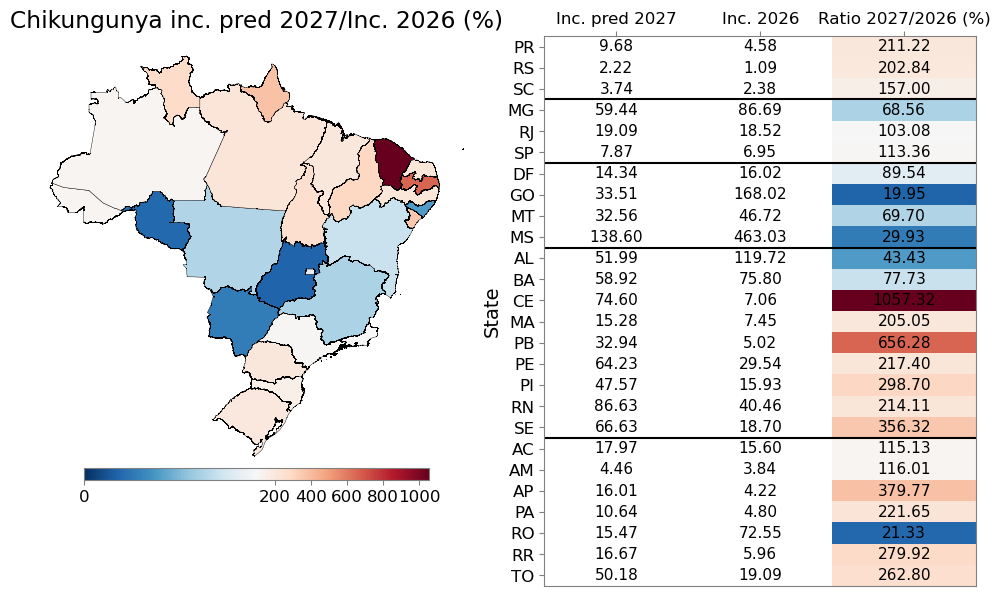

In [45]:
#_, ax = plt.subplots(1,2, figsize = (13, 10),  gridspec_kw={'width_ratios': [2.5, 1],
fig = plt.figure(figsize=(13, 10))
gs = gridspec.GridSpec(2, 2, width_ratios=[2,1.5], height_ratios=[2.5,1])

ax_map = fig.add_subplot(gs[0,0])   # map in top-left
ax_table = fig.add_subplot(gs[0,1]) # table in top-right                                     

column = 'ratio_inc'
# Define the center point (e.g., 0, or gdf[column].mean())

# Define normalization so colors diverge from the center
norm = mcolors.TwoSlopeNorm(
    #vmin=df_uf_m[column].min(),
    vmin=0,
    vcenter=100,
    vmax=df_uf_m[column].max()
)

df_uf_m.plot(
    column=column,
    cmap="RdBu_r",      # typical diverging colormap
    norm=norm,          # apply normalization
    linewidth=0.3,
    edgecolor="black",
    ax=ax_map,
    legend=True,
    legend_kwds={
        #"label": "",
        "orientation": "horizontal",  # or "vertical"
        "shrink": 0.6,                # make colorbar smaller
        "pad": 0.05,                  # space between map and colorbar
        "aspect": 30,                 # controls length/thickness
        "anchor": (0.5, 1.5)         # move colorbar (x, y)
    })

#df_uf_m.boundary.plot(ax=ax, color = 'black')
ax_map.axis('off')
#ax.legend()
#ax.legend(handles = handles, title = 'Model', bbox_to_anchor = (1.45, 0.95))

ax_map.set_title(f'{disease} inc. pred 2027/Inc. 2026 (%)')
 
cols = ['Inc. pred 2027', 'Inc. 2026', 'Ratio 2027/2026 (%)']
vals = df_pv[cols].values

color_data = np.ones((vals.shape[0], vals.shape[1], 4))

cmap = plt.cm.RdBu_r

for i in range(vals.shape[0]):
    rgba = cmap(norm(df_pv.loc[df_pv.index[i], 'Ratio 2027/2026 (%)']))
    color_data[i, -1, :] = rgba

ax_table.imshow(color_data, aspect='auto')

ax_table.set_xticks(np.arange(len(cols)))
ax_table.set_yticks(np.arange(len(df_pv)))
ax_table.set_xticklabels(cols)
ax_table.set_yticklabels(df_pv['uf'])

for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        text_val = vals[i, j]
        ax_table.text(j, i, f"{text_val:.2f}", ha="center", va="center", color="black", fontsize=11)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

ax_table.set_ylabel("State")
ax_table.set_xticklabels(cols, rotation=0, ha='center') 
ax_table.xaxis.set_ticks_position('top')
ax_table.xaxis.set_label_position('top')
#for j in range(1, vals.shape[0]):  # depois de cada coluna, exceto a primeira
ax_table.hlines(3 - 0.5, -0.5, vals.shape[1]-0.5, color='black', linewidth=1.5)
ax_table.hlines(6 - 0.5, -0.5, vals.shape[1]-0.5, color='black', linewidth=1.5)
ax_table.hlines(10 - 0.5, -0.5, vals.shape[1]-0.5, color='black', linewidth=1.5)
ax_table.hlines(19 - 0.5, -0.5, vals.shape[1]-0.5, color='black', linewidth=1.5)

plt.subplots_adjust(wspace=0, hspace=0)
#plt.tight_layout()

plt.savefig(f'figures/map_table_inc_2027_{challenge}.png', dpi = 400, bbox_inches = 'tight')
plt.show()
